# EDA: WHO Life Expectancy & Health Factors (2000–2015)
**Dataset:** Global Health Observatory (WHO) + UN Economic Data  
**Task:** Regression — Memprediksi Angka Harapan Hidup (Life Expectancy) 
**Scope:** 193 negara, tahun 2000–2015, 22 kolom 

---

## Pendekatan Analisis

EDA ini disusun dalam lima phase berurutan:

1. **Data Quality Audit** — Diagnosa missing values, zeros terselubung, 
   inkonsistensi logis, dan struktur panel
2. **Target Distribution & Segmentation** — Memahami distribusi Life 
   Expectancy dan struktur tersembunyi di dalamnya
3. **Correlation & Multicollinearity Mapping** — Identifikasi prediktor 
   terkuat dan redundansi antar fitur
4. **Thematic Deep-Dive** — Dua analisis tematik yang menghasilkan 
   insight substantif untuk prediksi
5. **Synthesis** — Konsolidasi semua temuan dan implikasinya untuk modeling


### Set Up

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# read file
df = pd.read_csv(r"Life Expectancy Data.csv")

# Reproducibility
np.random.seed(42)

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

## Phase 1: Data Quality Audit

Lima hal yang diperiksa:
- **Missing values** — berapa, di mana, dan apakah polanya bergantung pada `Status`?
- **Zeros tersembunyi** — nilai 0 yang sebenarnya adalah missing data
- **Konsistensi fitur** — constraint antar fitur berdasarkan definisi
- **Cek Kelengkapan Data** — apakah semua (Country, Year) pair lengkap?
- **Outlier** — membedakan noise dari signal yang legitimate

### Data Overview

In [2]:
df.shape

(2938, 22)

In [3]:
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling'],
      dtype='str')

In [4]:
# menghilangkan trailing whitespaces pada beberapa nama kolom
df.columns = df.columns.str.strip()

In [5]:
df.dtypes

Country                                str
Year                                 int64
Status                                 str
Life expectancy                    float64
Adult Mortality                    float64
infant deaths                        int64
Alcohol                            float64
percentage expenditure             float64
Hepatitis B                        float64
Measles                              int64
BMI                                float64
under-five deaths                    int64
Polio                              float64
Total expenditure                  float64
Diphtheria                         float64
HIV/AIDS                           float64
GDP                                float64
Population                         float64
thinness  1-19 years               float64
thinness 5-9 years                 float64
Income composition of resources    float64
Schooling                          float64
dtype: object

In [6]:
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.00,263.00,62,0.01,71.28,65.00,1154,19.10,83,6.00,8.16,65.00,0.10,584.26,33736494.00,17.20,17.30,0.48,10.10
1,Afghanistan,2014,Developing,59.90,271.00,64,0.01,73.52,62.00,492,18.60,86,58.00,8.18,62.00,0.10,612.70,327582.00,17.50,17.50,0.48,10.00
2,Afghanistan,2013,Developing,59.90,268.00,66,0.01,73.22,64.00,430,18.10,89,62.00,8.13,64.00,0.10,631.74,31731688.00,17.70,17.70,0.47,9.90
3,Afghanistan,2012,Developing,59.50,272.00,69,0.01,78.18,67.00,2787,17.60,93,67.00,8.52,67.00,0.10,669.96,3696958.00,17.90,18.00,0.46,9.80
4,Afghanistan,2011,Developing,59.20,275.00,71,0.01,7.10,68.00,3013,17.20,97,68.00,7.87,68.00,0.10,63.54,2978599.00,18.20,18.20,0.45,9.50


### Missing Values

In [7]:
# Menghitung missing values dari setiap kolom
missing = pd.DataFrame({
    'n_missing': df.isnull().sum(),
    'pct_missing': df.isnull().mean() * 100
}).sort_values('pct_missing', ascending=False)

missing = missing[missing['n_missing'] > 0]
print("=== Missing Value Profile ===")
print(missing.round(2))

# Apakah missing rate berbeda antara negara Developed dan Developing?
print("\n=== Missing Rate (%) by Development Status ===")
for col in missing.index:
    # Hitung missing rate per status
    rate_by_status = df.groupby('Status')[col].apply(
        lambda x: x.isnull().mean() * 100
    ).round(2)

    print(f"\n{col}:")
    print(rate_by_status.to_string())

=== Missing Value Profile ===
                                 n_missing  pct_missing
Population                             652        22.19
Hepatitis B                            553        18.82
GDP                                    448        15.25
Total expenditure                      226         7.69
Alcohol                                194         6.60
Income composition of resources        167         5.68
Schooling                              163         5.55
thinness  1-19 years                    34         1.16
thinness 5-9 years                      34         1.16
BMI                                     34         1.16
Diphtheria                              19         0.65
Polio                                   19         0.65
Life expectancy                         10         0.34
Adult Mortality                         10         0.34

=== Missing Rate (%) by Development Status ===

Population:
Status
Developed    18.75
Developing   22.92

Hepatitis B:
Status
Dev

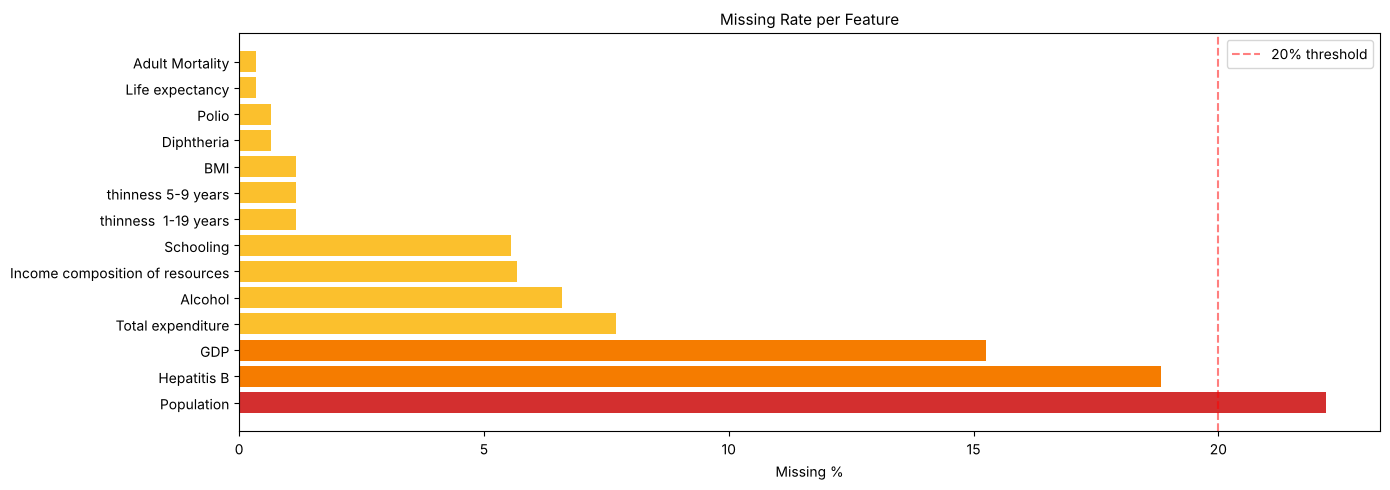

In [8]:
# Missing rate per fitur
fig, ax = plt.subplots(1, 1, figsize=(14, 5))
colors = ['#d32f2f' if p > 20 else '#f57c00' if p > 10 else '#fbc02d' for p in missing['pct_missing']]
ax.barh(missing.index, missing['pct_missing'], color=colors)
ax.axvline(20, color='red', linestyle='--', alpha=0.5, label='20% threshold')
ax.set_xlabel('Missing %')
ax.set_title('Missing Rate per Feature', fontsize=11)
ax.legend()

plt.tight_layout()
plt.show()

#### Temuan:
Missing rate dibandingkan antara negara Developed dan Developing. Ada tiga pola:

1. **Pola A — missing hanya di Developing.** `thinness`, `BMI`, `Diphtheria`, `Polio`, `Life expectancy`, dan `Adult Mortality` tidak punya missing sama sekali di Developed, tetapi punya sedikit missing (0,4–1,4%) di Developing.
2. **Pola B — missing lebih tinggi di Developed.** `Hepatitis B` (33,79% vs 15,66%), `Income composition of resources`, dan `Schooling`. Salah satu kemungkinan: negara maju tidak selalu melaporkan data imunisasi Hepatitis B ke WHO. Ini masih hipotesis.
3. **Pola C — missing rate mirip di kedua grup.** `GDP`, `Population`, `Total expenditure`, dan `Alcohol`. Tidak ada bukti bahwa missing-nya bergantung pada `Status`.

**Catatan istilah:** Pola A dan B menunjukkan bahwa missingness bergantung pada variabel yang teramati (`Status`). Ini konsisten dengan **MAR** (*Missing At Random*, bersyarat pada `Status`), bukan MNAR. MNAR (*Missing Not At Random*) berarti missingness bergantung pada nilai yang hilang itu sendiri, dan itu tidak bisa dibuktikan hanya dari data yang teramati. Penjelasan seperti "sistem pencatatan kesehatan yang buruk" adalah hipotesis, bukan hasil uji.

**Implikasi:** imputasi sebaiknya memperhitungkan `Status` atau tingkat pembangunan negara (misalnya imputasi per grup), bukan satu nilai global.

### Zeros Tersembunyi

In [9]:
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.00,2928.00,2928.00,2938.00,2744.00,2938.00,2385.00,2938.00,2904.00,2938.00,2919.00,2712.00,2919.00,2938.00,2490.00,2286.00,2904.00,2904.00,2771.00,2775.00
mean,2007.52,69.22,164.80,30.30,4.60,738.25,80.94,2419.59,38.32,42.04,82.55,5.94,82.32,1.74,7483.16,12753375.12,4.84,4.87,0.63,11.99
std,4.61,9.52,124.29,117.93,4.05,1987.91,25.07,11467.27,20.04,160.45,23.43,2.50,23.72,5.08,14270.17,61012096.51,4.42,4.51,0.21,3.36
min,2000.00,36.30,1.00,0.00,0.01,0.00,1.00,0.00,1.00,0.00,3.00,0.37,2.00,0.10,1.68,34.00,0.10,0.10,0.00,0.00
25%,2004.00,63.10,74.00,0.00,0.88,4.69,77.00,0.00,19.30,0.00,78.00,4.26,78.00,0.10,463.94,195793.25,1.60,1.50,0.49,10.10
50%,2008.00,72.10,144.00,3.00,3.75,64.91,92.00,17.00,43.50,4.00,93.00,5.75,93.00,0.10,1766.95,1386542.00,3.30,3.30,0.68,12.30
75%,2012.00,75.70,228.00,22.00,7.70,441.53,97.00,360.25,56.20,28.00,97.00,7.49,97.00,0.80,5910.81,7420359.00,7.20,7.20,0.78,14.30
max,2015.00,89.00,723.00,1800.00,17.87,19479.91,99.00,212183.00,87.30,2500.00,99.00,17.60,99.00,50.60,119172.74,1293859294.00,27.70,28.60,0.95,20.70


In [10]:
# Beberapa fitur memiliki nilai nol, padahal secara logis tidak mungkin 0 untuk negara yang punya data.
zero_cols = [
    'percentage expenditure',
    'Schooling', 
    'Income composition of resources',
]

print("=== Zero Value Analysis ===")
for col in zero_cols:
    if col in df.columns:
        n_zeros = (df[col] == 0).sum()
        pct_zeros = (df[col] == 0).mean() * 100
        print(f"{col}: {n_zeros} zeros ({pct_zeros:.1f}%)")

=== Zero Value Analysis ===
percentage expenditure: 611 zeros (20.8%)
Schooling: 28 zeros (1.0%)
Income composition of resources: 130 zeros (4.4%)


#### Temuan:
Fitur `percentage expenditure`, `Schooling`, dan `Income composition of resources` memiliki beberapa nilai nol. Secara logis nilai 0 tidak mungkin: tidak ada negara dengan rata-rata lama sekolah 0 tahun, indeks komposisi pendapatan 0, atau pengeluaran kesehatan 0. Kemungkinan besar data yang tidak tersedia di-encode sebagai 0 saat entri. Nilai-nilai nol ini diubah menjadi NaN.

In [11]:
cols = ['percentage expenditure', 'Schooling', 'Income composition of resources']
for col in cols:
    df[col] = df[col].replace(0, np.nan)

### Konsistensi Fitur

In [12]:
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.00,2928.00,2928.00,2938.00,2744.00,2327.00,2385.00,2938.00,2904.00,2938.00,2919.00,2712.00,2919.00,2938.00,2490.00,2286.00,2904.00,2904.00,2641.00,2747.00
mean,2007.52,69.22,164.80,30.30,4.60,932.09,80.94,2419.59,38.32,42.04,82.55,5.94,82.32,1.74,7483.16,12753375.12,4.84,4.87,0.66,12.12
std,4.61,9.52,124.29,117.93,4.05,2192.97,25.07,11467.27,20.04,160.45,23.43,2.50,23.72,5.08,14270.17,61012096.51,4.42,4.51,0.16,3.15
min,2000.00,36.30,1.00,0.00,0.01,0.10,1.00,0.00,1.00,0.00,3.00,0.37,2.00,0.10,1.68,34.00,0.10,0.10,0.25,2.80
25%,2004.00,63.10,74.00,0.00,0.88,36.25,77.00,0.00,19.30,0.00,78.00,4.26,78.00,0.10,463.94,195793.25,1.60,1.50,0.52,10.20
50%,2008.00,72.10,144.00,3.00,3.75,155.20,92.00,17.00,43.50,4.00,93.00,5.75,93.00,0.10,1766.95,1386542.00,3.30,3.30,0.69,12.40
75%,2012.00,75.70,228.00,22.00,7.70,630.22,97.00,360.25,56.20,28.00,97.00,7.49,97.00,0.80,5910.81,7420359.00,7.20,7.20,0.78,14.30
max,2015.00,89.00,723.00,1800.00,17.87,19479.91,99.00,212183.00,87.30,2500.00,99.00,17.60,99.00,50.60,119172.74,1293859294.00,27.70,28.60,0.95,20.70


In [13]:
# Identifikasi baris dengan BMI mencurigakan
bmi_suspect = df[df['BMI'] < 10][['Country', 'Year', 'BMI', 'Life expectancy']].sort_values('BMI')
print(f"Baris dengan BMI < 10: {len(bmi_suspect)}")
print(bmi_suspect)

# Rata-rata BMI populasi umumnya berada di kisaran ~18–32.
# Nilai di atas 40 juga tidak masuk akal sebagai rata-rata nasional.
print(f"\nBaris dengan BMI > 40: {(df['BMI'] > 40).sum()} dari {df['BMI'].notna().sum()} baris non-missing")

Baris dengan BMI < 10: 283
         Country  Year  BMI  Life expectancy
2887    Viet Nam  2002 1.00            73.80
2886    Viet Nam  2003 1.40            74.00
207   Bangladesh  2000 1.40            65.30
206   Bangladesh  2001 1.80            65.80
2885    Viet Nam  2004 1.90            74.20
...          ...   ...  ...              ...
1395      Kuwait  2014 7.80            74.60
2641       Tonga  2007 7.80            72.50
2208       Samoa  2007 7.90            72.20
2889    Viet Nam  2000 9.20            73.40
2888    Viet Nam  2001 9.60            73.60

[283 rows x 4 columns]

Baris dengan BMI > 40: 1528 dari 2904 baris non-missing


In [14]:
# Investigasi negara dengan populasi terkecil
print(df.nsmallest(10, 'Population')[['Country', 'Year', 'Population']])

       Country  Year  Population
1614  Maldives  2003       34.00
1608  Maldives  2009       36.00
1603  Maldives  2014       41.00
985    Georgia  2008       43.00
1159   Hungary  2010      123.00
2640     Tonga  2008      135.00
2644     Tonga  2004      146.00
1617  Maldives  2000      286.00
1616  Maldives  2001      292.00
1958     Palau  2013      292.00


In [15]:
# Investigasi negara dengan Measles tertinggi
print(df.nlargest(5, 'Measles')[['Country', 'Year', 'Measles', 'Population']])

                               Country  Year  Measles   Population
1908                           Nigeria  2000   212183   1223529.00
731   Democratic Republic of the Congo  2005   182485          NaN
1907                           Nigeria  2001   168107 125463434.00
1905                           Nigeria  2003   141258 131972533.00
725   Democratic Republic of the Congo  2011   133802          NaN


In [16]:
# Investigasi negara dengan infant deaths dan under-five deaths tertinggi
print("infant deaths max:")
print(df.nlargest(5, 'infant deaths')[['Country', 'Year', 'infant deaths', 'Population']])
print("\nunder-five deaths max:")  
print(df.nlargest(5, 'under-five deaths')[['Country', 'Year', 'under-five deaths', 'Population']])

infant deaths max:
     Country  Year  infant deaths    Population
1200   India  2001           1800  171477855.00
1201   India  2000           1800    1535912.00
1198   India  2003           1700   11827848.00
1199   India  2002           1700   18987112.00
1197   India  2004           1600 1126135777.00

under-five deaths max:
     Country  Year  under-five deaths    Population
1201   India  2000               2500    1535912.00
1200   India  2001               2400  171477855.00
1199   India  2002               2300   18987112.00
1198   India  2003               2200   11827848.00
1197   India  2004               2100 1126135777.00


In [17]:
# Investigasi negara dengan percentage expenditure tertinggi
print("Negara dengan percentage expenditure tertinggi:")
print(df.nlargest(5, 'percentage expenditure')[['Country', 'Year', 'percentage expenditure','GDP', 'Population']])
print("\nNegara dengan percentage expenditure terendah:")
print(df.nsmallest(5, 'percentage expenditure')[['Country', 'Year', 'percentage expenditure','GDP', 'Population']])

Negara dengan percentage expenditure tertinggi:
          Country  Year  percentage expenditure       GDP  Population
2522  Switzerland  2014                19479.91  85814.59  8188649.00
2523  Switzerland  2013                19099.05  84658.89   889346.00
1545   Luxembourg  2008                18961.35 114293.84    48865.00
2525  Switzerland  2011                18822.87  87998.44  7912398.00
2524  Switzerland  2012                18379.33  83164.39  7996861.00

Negara dengan percentage expenditure terendah:
           Country  Year  percentage expenditure   GDP  Population
2036   Philippines  2002                    0.10  1.68   813526.00
1672     Mauritius  2010                    0.11  8.38     1254.00
2584      Thailand  2000                    0.28 27.56  6295821.00
479       Cambodia  2000                    0.33  3.69 12152354.00
2705  Turkmenistan  2007                    0.36 26.37   487137.00


In [18]:
print("Rata-rata rasio Percentage Expenditure / GDP:")
print((df['percentage expenditure'] / df['GDP']).dropna().mean())

Rata-rata rasio Percentage Expenditure / GDP:
0.10317236785597438


#### Temuan:
1. **BMI.** Ada 283 baris dengan nilai di bawah 10, bahkan sampai 1. Ini tidak masuk akal secara medis, kemungkinan kesalahan input. Masalahnya lebih besar dari itu: lebih dari separuh baris punya BMI di atas 40, padahal rata-rata BMI suatu negara umumnya berada di kisaran ~18–32. Artinya unit atau definisi kolom ini kemungkinan tidak sesuai dengan namanya. Di notebook ini, nilai < 10 diubah menjadi NaN, tetapi kolom `BMI` secara keseluruhan perlu diperlakukan dengan hati-hati.
2. **Population.** Populasi Maldives tahun 2003 tercatat 34, padahal populasi aktualnya sekitar 293 ribu. Populasi India tahun 2000 tercatat 1.535.912, tetapi tahun 2001 tercatat 171.477.855, beda lebih dari 100 kali lipat dalam setahun. Fitur ini punya error yang parah dan tidak layak dipakai sebagai prediktor.
3. **Measles.** Di overview dataset, `Measles` didefinisikan sebagai jumlah kasus campak per 1000 populasi. Namun banyak nilai di atas 1000. Ada dua kemungkinan: datanya sebenarnya jumlah kasus absolut (*absolute count*), atau ada kesalahan entri.
4. **Infant deaths dan under-five deaths.** Masalahnya sama: di overview tertulis per 1000 populasi, tetapi ada nilai di atas 1000.
5. **Percentage expenditure.** Banyak nilai di atas 100, bahkan ada yang di atas 19.000. Ini tidak masuk akal untuk persentase pengeluaran kesehatan terhadap GDP per kapita. Rata-rata rasio `percentage expenditure / GDP` sekitar 0,1, sehingga kolom ini kemungkinan berisi nilai pengeluaran kesehatan per kapita (nilai absolut, sekitar 10% dari GDP per kapita), bukan persentase.

In [19]:
# Treat BMI < 10 sebagai impossible value, ubah jadi NaN
# (nilai BMI > 40 tidak diubah, tapi kolom ini tetap dicatat sebagai tidak reliable)
df.loc[df['BMI'] < 10, 'BMI'] = np.nan

In [20]:
# Cek Konsistensi Antar Fitur

print("=== Logical Consistency Violations ===\n")

# Cek infant deaths harus ≤ under-five deaths
mask1 = df['infant deaths'] > df['under-five deaths']
print(f"[1] infant deaths > under-five deaths: {mask1.sum()} violations")
if mask1.sum() > 0:
    print(df[mask1][['Country', 'Year', 'infant deaths', 'under-five deaths']].head())

# Cek thinness 5-9 years harus ≤ thinness 1-19 years
mask2 = df['thinness 5-9 years'] > df['thinness  1-19 years']
# Perhatian: nama kolom 'thinness  1-19 years' punya double space di dataset asli
print(f"\n[2] thinness 5-9 > thinness 1-19: {mask2.sum()} violations")

# Cek life expectancy dalam range yang masuk akal
le_range = df['Life expectancy'].describe()
print(f"\n[3] Life expectancy range: {le_range['min']:.1f} - {le_range['max']:.1f}")
extreme_le = df[df['Life expectancy'] < 40][['Country', 'Year', 'Life expectancy']]
if len(extreme_le) > 0:
    print(f"Extreme low (<40 years):\n{extreme_le}")

# Cek semua persentase (imunisasi) harus 0-100
for col in ['Hepatitis B', 'Polio', 'Diphtheria']:
    n_over_100 = (df[col] > 100).sum()
    print(f"\n[4] {col} > 100%: {n_over_100} violations")

=== Logical Consistency Violations ===

[1] infant deaths > under-five deaths: 0 violations

[2] thinness 5-9 > thinness 1-19: 662 violations

[3] Life expectancy range: 36.3 - 89.0
Extreme low (<40 years):
           Country  Year  Life expectancy
1127         Haiti  2010            36.30
2312  Sierra Leone  2000            39.00

[4] Hepatitis B > 100%: 0 violations

[4] Polio > 100%: 0 violations

[4] Diphtheria > 100%: 0 violations


#### Temuan:
1. Ada 662 baris dengan nilai `thinness 5-9 years` > `thinness 1-19 years`. Ini bukan pelanggaran logika. Kedua kolom berupa persentase (prevalensi), dan prevalensi pada satu kelompok umur bisa lebih tinggi daripada prevalensi pada kelompok umur yang lebih lebar.
2. Ada dua baris dengan Life Expectancy di bawah 40 tahun: Haiti 2010 dan Sierra Leone 2000. Secara statistik keduanya outlier, tetapi nilainya masuk akal (bukan error data). Haiti mengalami gempa bumi besar pada 12 Januari 2010 dengan estimasi korban jiwa sekitar 100.000 hingga lebih dari 300.000 orang. Sierra Leone mengalami perang saudara pada 1991–2002. Kedua baris ini dipertahankan.

### Cek Kelengkapan Data

In [21]:
years_per_country = df.groupby('Country')['Year'].nunique().sort_values()

print("=== Cek Kelengkapan Data ===")
print(f"Tahun unik: {sorted(df['Year'].unique())}")
print(f"Jumlah negara: {df['Country'].nunique()}")
print(f"\nNegara dengan data TIDAK lengkap (< 16 tahun):")
incomplete = years_per_country[years_per_country < 16]
print(incomplete)
print(f"\nTotal negara tidak lengkap: {len(incomplete)}")

=== Cek Kelengkapan Data ===
Tahun unik: [np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]
Jumlah negara: 193

Negara dengan data TIDAK lengkap (< 16 tahun):
Country
Dominica                 1
Cook Islands             1
Niue                     1
Nauru                    1
Monaco                   1
Marshall Islands         1
Saint Kitts and Nevis    1
Palau                    1
Tuvalu                   1
San Marino               1
Name: Year, dtype: int64

Total negara tidak lengkap: 10


#### Temuan:
Ada 10 negara yang datanya tidak lengkap, dan semuanya hanya punya data 1 tahun. Kemungkinan ini keterbatasan data WHO, karena kesepuluh negara tersebut adalah negara kecil. Negara-negara ini tidak bisa dipakai untuk analisis temporal, tetapi masih bisa dipakai untuk analisis non-temporal dan dimasukkan ke dalam model.

In [22]:
# Membuat df_temporal untuk analisis temporal (hanya negara dengan data lengkap)
incomplete_countries = years_per_country[years_per_country < 16].index.tolist()
df_temporal = df[~df['Country'].isin(incomplete_countries)].copy()
# df (full) tetap ada untuk analisis non-temporal

### Outliers

In [23]:
# Cek Outliers dengan IQR method

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ['Year']]

outlier_summary = {}
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = {
        'n_outliers': n_outliers,
        'pct_outliers': round(n_outliers / len(df) * 100, 2),
        'lower_bound': round(lower, 2),
        'upper_bound': round(upper, 2)
    }

outlier_df = pd.DataFrame(outlier_summary).T.sort_values('pct_outliers', ascending=False)
print("=== Outlier Summary (IQR method) ===")
print(outlier_df[outlier_df['n_outliers'] > 0])

=== Outlier Summary (IQR method) ===
                        n_outliers  pct_outliers  lower_bound  upper_bound
Measles                     542.00         18.45      -540.38       900.62
HIV/AIDS                    542.00         18.45        -0.95         1.85
under-five deaths           394.00         13.41       -42.00        70.00
GDP                         365.00         12.42     -7706.37     14081.11
percentage expenditure      325.00         11.06      -854.72      1521.18
infant deaths               315.00         10.72       -33.00        55.00
Diphtheria                  298.00         10.14        49.50       125.50
Population                  294.00         10.01 -10641055.38  18257207.62
Polio                       279.00          9.50        49.50       125.50
Hepatitis B                 254.00          8.65        47.00       127.00
thinness 5-9 years           96.00          3.27        -7.05        15.75
thinness  1-19 years         89.00          3.03        -6.80  

#### Temuan:
Beberapa fitur memiliki proporsi outlier yang besar, bahkan di atas 15% (`Measles` dan `HIV/AIDS`). Ini masih masuk akal karena beberapa negara memang punya nilai yang jauh lebih tinggi daripada mayoritas negara lain. Contohnya, negara dengan populasi sangat besar seperti India wajar punya jumlah kasus campak yang jauh lebih banyak (jika `Measles` memang absolute count). Contoh lain, negara seperti Swaziland dan Zimbabwe punya angka HIV/AIDS puluhan kali lebih tinggi daripada banyak negara yang angkanya di bawah 1.

Jadi outlier di fitur-fitur count/rate ini mencerminkan distribusi yang sangat *right-skewed*, bukan error. Fitur-fitur tersebut ditransformasi dengan `log1p`. Outlier pada fitur imunisasi (`Polio`, `Diphtheria`, `Hepatitis B`) berada di sisi bawah (coverage rendah), sehingga tidak ikut di-log.

In [24]:
# Log Transforms untuk kolom yang sangat right skewed
cols = ['GDP', 'percentage expenditure', 'Measles', 'under-five deaths','infant deaths', 'Population', 'HIV/AIDS']
for col in cols:
    df[f'log_{col}'] = np.log1p(df[col])  # log1p handle zeros/NaN dengan aman

### Temuan Phase 1 — Ringkasan

| Masalah | Detail | Keputusan |
|---|---|---|
| **Missing bergantung pada `Status`** | Pola A (hanya di Developing), Pola B (lebih tinggi di Developed, misalnya HepB), Pola C (mirip di kedua grup). Pola A dan B konsisten dengan MAR terhadap `Status`. | Imputasi perlu memperhitungkan `Status`/tingkat pembangunan (belum diterapkan di EDA ini) |
| **Zeros tersembunyi** | `percentage expenditure`, `Schooling`, `Income composition of resources`: missing ter-encode sebagai 0 | Replace 0 → NaN |
| **Nilai tidak masuk akal** | `BMI` < 10 (283 baris) dan mayoritas `BMI` > 40; `Population` tidak konsisten; `Measles`, `infant deaths`, `under-five deaths`, `percentage expenditure` tidak sesuai definisi | BMI < 10 → NaN; `Population` di-drop di Phase 3; fitur lain dicatat sebagai keterbatasan |
| **Kelengkapan data** | 10 negara kecil hanya punya 1 tahun data | Dikeluarkan dari analisis temporal |
| **Outliers** | Fitur count sangat right-skewed; Haiti 2010 (36,3 tahun, gempa) dan Sierra Leone 2000 (39,0 tahun, perang saudara) | Log transform untuk fitur skewed; Haiti dan Sierra Leone dipertahankan |

## Phase 2: Target Distribution & Segmentation

Target variabel (`Life expectancy`) dianalisis dari tiga sudut:
1. Distribusi global dan normalitas
2. Segmentasi Developed vs Developing — seberapa berbeda kedua grup?
3. Tren temporal — apakah life expectancy konvergen?

### Analysis

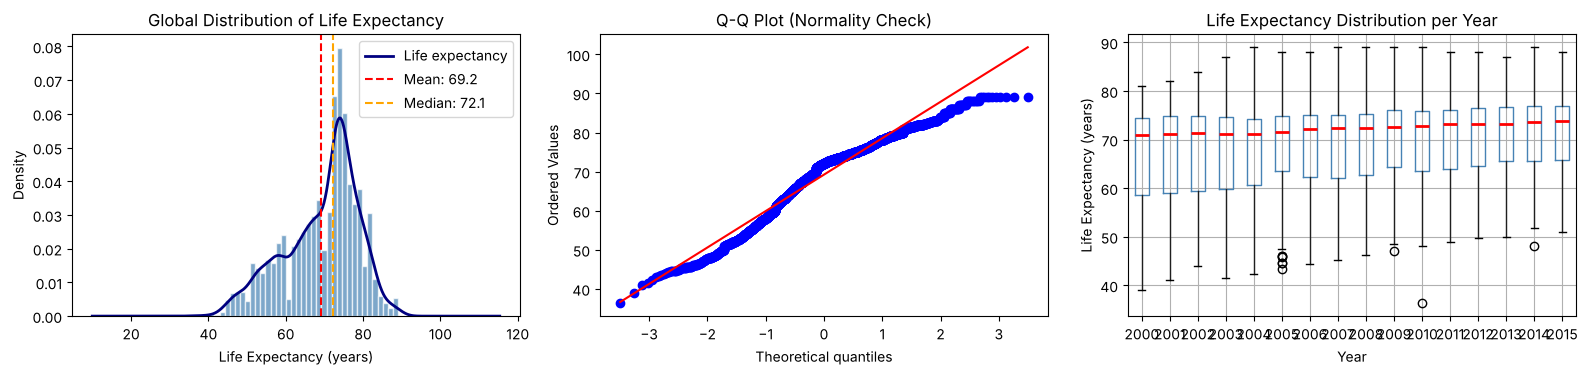

=== Descriptive Statistics: Life Expectancy ===
count   2928.00
mean      69.22
std        9.52
min       36.30
25%       63.10
50%       72.10
75%       75.70
max       89.00
Name: Life expectancy, dtype: float64

Skewness : -0.6386
Kurtosis : -0.2345


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

le = df['Life expectancy'].dropna()

# Plot 1: Histogram + KDE
axes[0].hist(le, bins=40, color='steelblue', alpha=0.7, density=True, edgecolor='white')
le.plot.kde(ax=axes[0], color='navy', linewidth=2)
axes[0].axvline(le.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {le.mean():.1f}')
axes[0].axvline(le.median(), color='orange', linestyle='--', linewidth=1.5, label=f'Median: {le.median():.1f}')
axes[0].set_title('Global Distribution of Life Expectancy')
axes[0].set_xlabel('Life Expectancy (years)')
axes[0].legend()

# Plot 2: QQ-plot
from scipy.stats import probplot
probplot(le, plot=axes[1])
axes[1].set_title('Q-Q Plot (Normality Check)')

# Plot 3: Boxplot per tahun (untuk melihat tren global)
df.boxplot(column='Life expectancy', by='Year', ax=axes[2], 
           boxprops=dict(color='steelblue'),
           medianprops=dict(color='red', linewidth=2))
axes[2].set_title('Life Expectancy Distribution per Year')
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Life Expectancy (years)')
plt.suptitle('') 
fig.suptitle('')

plt.tight_layout()
plt.show()

# Statistik deskriptif
print("=== Descriptive Statistics: Life Expectancy ===")
print(le.describe())
print(f"\nSkewness : {le.skew():.4f}")
print(f"Kurtosis : {le.kurtosis():.4f}")

Skewness −0,64 dan mean (69,2) < median (72,1). Artinya lebih dari separuh observasi (negara-tahun) berada di atas rata-rata, dan nilai mean ditarik ke bawah oleh negara-negara dengan life expectancy yang jauh lebih rendah. Q-Q plot mengonfirmasi hal ini: ekor kiri menyimpang dari garis normal.

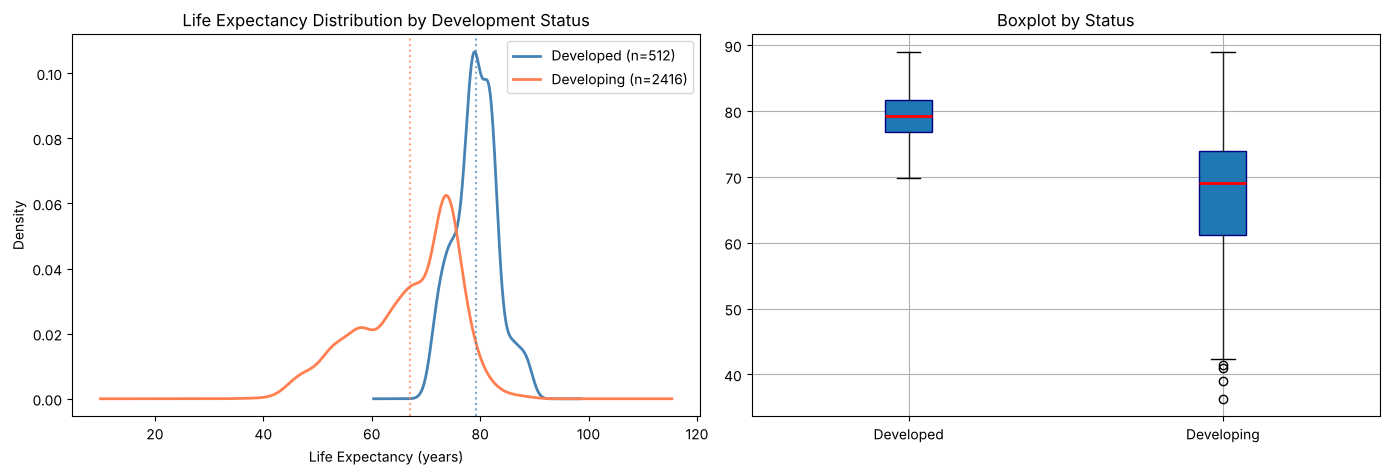

=== Group Comparison: Developed vs Developing ===

Developed   — Mean: 79.20, Std: 3.93, Median: 79.25
Developing  — Mean: 67.11, Std: 9.01, Median: 69.00

Gap (mean)  : 12.09 tahun


In [26]:
# Segmentasi berdasarkan Status (Developed vs Developing)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

developed = df[df['Status'] == 'Developed']['Life expectancy'].dropna()
developing = df[df['Status'] == 'Developing']['Life expectancy'].dropna()

# Plot 1: KDE (Developed vs Developing)
developed.plot.kde(ax=axes[0], label=f'Developed (n={len(developed)})', 
                   color='steelblue', linewidth=2)
developing.plot.kde(ax=axes[0], label=f'Developing (n={len(developing)})', 
                    color='coral', linewidth=2)

axes[0].set_title('Life Expectancy Distribution by Development Status')
axes[0].set_xlabel('Life Expectancy (years)')
axes[0].legend()
axes[0].axvline(developed.mean(), color='steelblue', linestyle=':', alpha=0.7)
axes[0].axvline(developing.mean(), color='coral', linestyle=':', alpha=0.7)

# Plot 2: Boxplot (Developed vs Developing)
df.boxplot(column='Life expectancy', by='Status', ax=axes[1],
           boxprops=dict(color='navy'),
           medianprops=dict(color='red', linewidth=2),
           patch_artist=True)
axes[1].set_title('Boxplot by Status')
axes[1].set_xlabel('')
plt.suptitle('')

plt.tight_layout()
plt.show()

print("=== Group Comparison: Developed vs Developing ===")
print(f"\nDeveloped   — Mean: {developed.mean():.2f}, Std: {developed.std():.2f}, "
      f"Median: {developed.median():.2f}")
print(f"Developing  — Mean: {developing.mean():.2f}, Std: {developing.std():.2f}, "
      f"Median: {developing.median():.2f}")
print(f"\nGap (mean)  : {developed.mean() - developing.mean():.2f} tahun")

Distribusi Life Expectancy negara Developed dan Developing sangat berbeda.
- **Developed:** unimodal (satu puncak), terpusat di ~79 tahun, dan sempit (std = 3,93). Negara maju sudah punya life expectancy tinggi, sehingga ruang untuk naik lebih kecil.
- **Developing:** bimodal (dua puncak), terlihat di KDE sekitar ~60 dan ~72 tahun. Variansinya jauh lebih besar (std = 9,01).

Gap 2000: 12.18 tahun
Gap 2015: 11.02 tahun
Perubahan: -1.16 tahun (-9.6%)


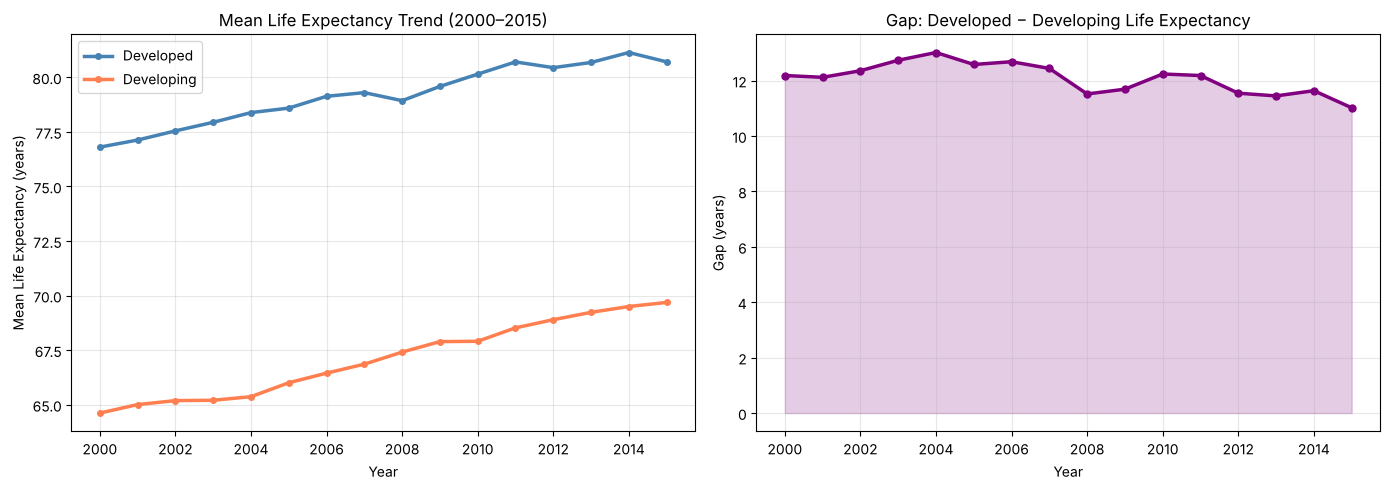

In [27]:
# Membandingkan gap antara negara Developed dan Developing dari tahun ke tahun

trend = df_temporal.groupby(['Year', 'Status'])['Life expectancy'].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Tren life expectancy (developed vs developing)
for status, color in [('Developed', 'steelblue'), ('Developing', 'coral')]:
    subset = trend[trend['Status'] == status]
    axes[0].plot(subset['Year'], subset['Life expectancy'], 
                 color=color, linewidth=2.5, marker='o', markersize=4, label=status)
    
axes[0].set_title('Mean Life Expectancy Trend (2000–2015)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Mean Life Expectancy (years)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Gap trend, melihat apakah selisih antara Developed dan Developing menyempit atau melebar
pivot = trend.pivot(index='Year', columns='Status', values='Life expectancy')
pivot['Gap'] = pivot['Developed'] - pivot['Developing']
axes[1].plot(pivot.index, pivot['Gap'], color='purple', linewidth=2.5, marker='o', markersize=5)
axes[1].fill_between(pivot.index, pivot['Gap'], alpha=0.2, color='purple')
axes[1].set_title('Gap: Developed − Developing Life Expectancy')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Gap (years)')
axes[1].grid(alpha=0.3)

# Hitung rate of convergence
gap_2000 = pivot.loc[2000, 'Gap']
gap_2015 = pivot.loc[2015, 'Gap']
print(f"Gap 2000: {gap_2000:.2f} tahun")
print(f"Gap 2015: {gap_2015:.2f} tahun")
print(f"Perubahan: {gap_2015 - gap_2000:.2f} tahun ({((gap_2015-gap_2000)/gap_2000*100):.1f}%)")

plt.tight_layout()
plt.show()

Dalam 15 tahun, gap life expectancy antara negara Developed dan Developing hanya turun 1,16 tahun (9,6%). Jika ekstrapolasi linear dengan laju yang sama (~0,08 tahun per tahun), gap sebesar 11,02 tahun pada 2015 baru tertutup sekitar 140 tahun kemudian. Ini hanya ilustrasi kasar, bukan prediksi.

Tren menunjukkan kedua kategori naik hampir paralel, dengan laju yang sedikit berbeda karena negara maju punya ruang pertumbuhan yang lebih kecil. Ada sedikit penurunan pada kategori Developed sekitar 2008. Salah satu kemungkinan adalah dampak krisis finansial 2008, tetapi ini belum diuji dan bisa juga sekadar noise atau artefak data.

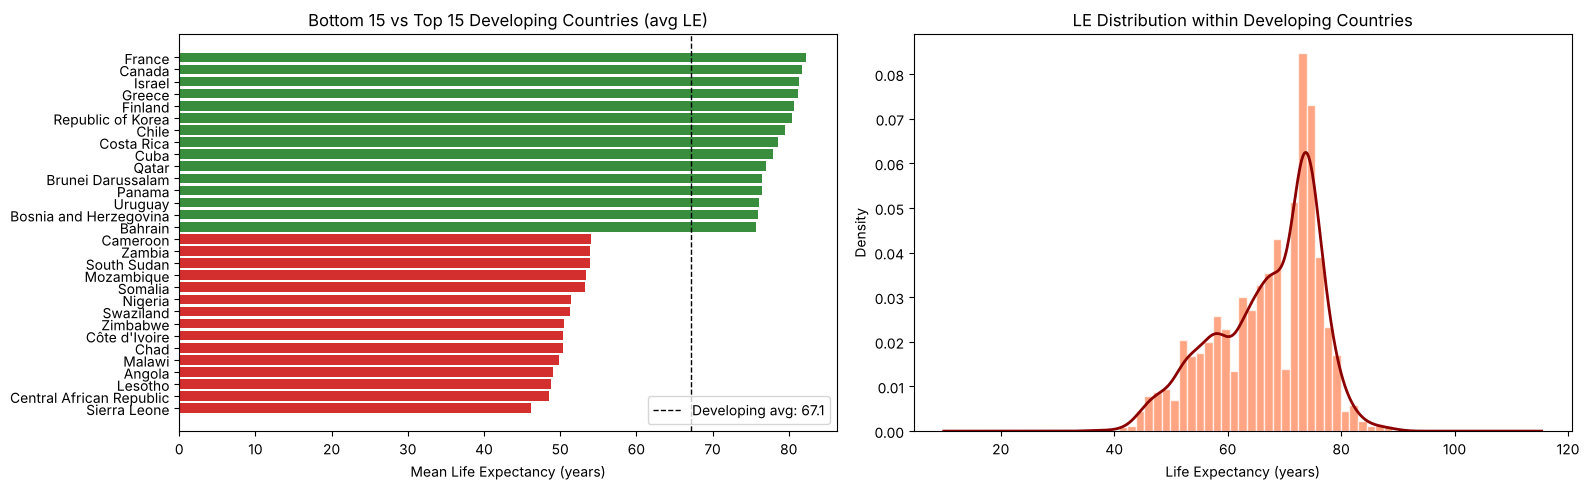

=== Spread within Developing Countries ===
Min  : 46.1 (Sierra Leone)
Max  : 82.2 (France)
Range: 36.1 tahun
Std  : 8.63


In [28]:
# Distribusi Life Expectancy dalam Developing Country

developing_df = df_temporal[df_temporal['Status'] == 'Developing'].copy()

country_avg = developing_df.groupby('Country')['Life expectancy'].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: 15 terbawah vs 15 teratas di Developing
top15 = country_avg.tail(15)
bot15 = country_avg.head(15)
combined = pd.concat([bot15, top15])

colors = ['#d32f2f'] * 15 + ['#388e3c'] * 15
axes[0].barh(combined.index, combined.values, color=colors)
axes[0].axvline(country_avg.mean(), color='black', linestyle='--', 
                linewidth=1, label=f'Developing avg: {country_avg.mean():.1f}')
axes[0].set_title('Bottom 15 vs Top 15 Developing Countries (avg LE)')
axes[0].set_xlabel('Mean Life Expectancy (years)')
axes[0].legend()

# Plot 2: Histogram distribusi LE di Developing
developing_df['Life expectancy'].dropna().hist(
    ax=axes[1], bins=35, color='coral', alpha=0.7, edgecolor='white', density=True
)
developing_df['Life expectancy'].dropna().plot.kde(ax=axes[1], color='darkred', linewidth=2)
axes[1].set_title('LE Distribution within Developing Countries')
axes[1].set_xlabel('Life Expectancy (years)')

plt.tight_layout()
plt.show()

# Print spread statistik
print("=== Spread within Developing Countries ===")
print(f"Min  : {country_avg.min():.1f} ({country_avg.idxmin()})")
print(f"Max  : {country_avg.max():.1f} ({country_avg.idxmax()})")
print(f"Range: {country_avg.max() - country_avg.min():.1f} tahun")
print(f"Std  : {country_avg.std():.2f}")

Terlihat bahwa Developing Country memiliki penyebaran data yang lumayan besar dengan Range=36.1 dan std=8.63. Tetapi terlihat bahwa pada negara-negara yang memiliki life expectancy tertinggi di kategori developing, terdapat beberapa negara yang jelas-jelas bukan negara berkembang (Contohnya: France, Canada, Israel, Greece, Finland). Sepertinya ini adalah mislabeled dari dataset WHO.

In [29]:
# Identifikasi anomali klasifikasi Status
high_le_developing = (
    df[df['Status'] == 'Developing']
    .groupby('Country')[['Life expectancy', 'GDP', 'Schooling']]
    .mean()
    .sort_values('Life expectancy', ascending=False)
    .head(20)
    .round(2)
)
print(high_le_developing)

# Berapa banyak "Developing" yang GDP-nya lebih tinggi dari median Developed?
median_gdp_developed = df[df['Status'] == 'Developed']['GDP'].median()
misclassified_suspects = (
    df[df['Status'] == 'Developing']
    .groupby('Country')['GDP'].mean()
    [lambda x: x > median_gdp_developed]
)
print(f"\nNegara 'Developing' dengan GDP > median Developed: {len(misclassified_suspects)}")
print(misclassified_suspects.sort_values(ascending=False).head(10))

                        Life expectancy      GDP  Schooling
Country                                                    
France                            82.22 26465.55      15.90
Canada                            81.69 29382.91      15.88
Israel                            81.30 18860.48      15.71
Greece                            81.22 16454.24      15.94
Finland                           80.71 25268.65      17.29
Republic of Korea                 80.49      NaN        NaN
Chile                             79.45  6202.34      14.90
Costa Rica                        78.59  3957.23      12.84
Cuba                              77.97  3180.43      14.69
Qatar                             77.03 40748.44      12.85
Brunei Darussalam                 76.49 19744.81      14.11
Panama                            76.49  5417.77      12.78
Uruguay                           76.08  7192.58      15.23
Bosnia and Herzegovina            75.97  2245.03      13.04
Bahrain                           75.72 

Terdapat 9 negara yang memiliki GDP di atas median Developed Country. Negara-negara tersebut bisa jadi mislabeled dan mungkin saja ada juga negara lain (di luar kesembilan negara tersebut) yang mislabeled juga. Tetapi kita tidak bisa menentukan Kategori negara hanya dari GDP saja. Daripada bergantung pada fitur status yang kemungkinan memiliki beberapa mislabel, lebih baik untuk membuat index kemajuan sebuah negara (development_index) yang dibentuk dari fitur Schooling, Income composition of resources, dan log_GDP.

In [30]:
# Membuat development proxy index
# Tiga fitur yang digunakan:
# - Schooling: akses pendidikan (Human Development Index component)
# - Income composition of resources: Human Development Index component
# - log_GDP: economic output per capita

from sklearn.preprocessing import StandardScaler

proxy_cols = ['Schooling', 'Income composition of resources', 'log_GDP']

df_proxy_filled = df[proxy_cols].copy()
for col in proxy_cols:
    # isi missing dengan rata-rata per Status
    group_mean = df.groupby('Status')[col].transform('mean')
    df_proxy_filled[col] = df_proxy_filled[col].fillna(group_mean)

# Standardize
scaler = StandardScaler()
df_proxy_scaled = pd.DataFrame(
    scaler.fit_transform(df_proxy_filled),
    columns=proxy_cols,
    index=df.index
)
df['development_index'] = df_proxy_scaled.mean(axis=1)

# --- Validasi: apakah index ini lebih konsisten dari Status biner? ---
validation = (
    df.groupby('Country')[['development_index', 'Life expectancy']]
    .mean()
    .sort_values('development_index', ascending=False)
)
validation['Status'] = df.groupby('Country')['Status'].first()

print("=== Top 15 by Development Index ===")
print(validation.head(15).round(3))

print("\n=== Bottom 15 by Development Index ===")
print(validation.tail(15).round(3))

# Cek: apakah France/Canada sekarang berada di posisi yang benar?
print("\n=== Spot Check: Previously Misclassified Countries ===")
spot = ['France', 'Canada', 'Israel', 'Greece', 'Finland', 
        'Qatar', 'Kuwait', 'Sierra Leone', 'Chad']
print(validation.loc[[c for c in spot if c in validation.index]].round(3))

=== Top 15 by Development Index ===
             development_index  Life expectancy      Status
Country                                                    
Australia                 1.85            81.81   Developed
Ireland                   1.59            80.15   Developed
Netherlands               1.55            81.13   Developed
Iceland                   1.54            82.44   Developed
Switzerland               1.52            82.33   Developed
Denmark                   1.52            79.26   Developed
New Zealand               1.51            81.34   Developed
Norway                    1.49            81.79   Developed
Finland                   1.42            80.71  Developing
Germany                   1.41            81.17   Developed
Sweden                    1.36            82.52   Developed
Canada                    1.36            81.69  Developing
Belgium                   1.29            80.68   Developed
France                    1.27            82.22  Developing
Aust

In [31]:
corr_di = df[['development_index', 'Life expectancy']].corr().iloc[0, 1]
df['Status_encoded'] = (df['Status'] == 'Developed').astype(int)
corr_status = df[['Status_encoded', 'Life expectancy']].corr().iloc[0, 1]
print(f"Korelasi Development Index vs LE : {corr_di:.4f}")
print(f"Korelasi Status (biner) vs LE    : {corr_status:.4f}")

Korelasi Development Index vs LE : 0.8002
Korelasi Status (biner) vs LE    : 0.4821


In [32]:
check_country = 'Republic of Korea'

print(df[df['Country'] == check_country][
    ['Country', 'Schooling', 'Income composition of resources', 'log_GDP']
].groupby('Country').mean().round(3))
print()
print(df[df['Country'] == check_country].groupby('Country')['development_index'].mean().round(3))

                   Schooling  Income composition of resources  log_GDP
Country                                                               
Republic of Korea        NaN                              NaN      NaN

Country
Republic of Korea   -0.24
Name: development_index, dtype: float64


Development Index punya korelasi yang jauh lebih tinggi dengan Life Expectancy dibandingkan `Status` (r = 0,80 vs r = 0,48). Artinya Development Index adalah fitur yang jauh lebih informatif sebagai prediktor dibandingkan label `Status`.

Namun Development Index juga punya keterbatasan, terutama pada negara yang mislabeled dan punya missing data pada `Schooling`, `Income composition of resources`, dan `GDP`. Contohnya Republic of Korea, yang Development Index-nya hanya −0,24. Nilainya rendah karena Korea berlabel Developing dan ketiga fiturnya bernilai NaN, sehingga diisi dengan rata-rata negara berstatus Developing.

### Temuan Phase 2 — Ringkasan

**Distribusi global:** skewness −0,64 (left-skewed). Lebih dari separuh observasi berada di atas rata-rata (69,2 tahun).

**Dua populasi berbeda:**
Sebaran kedua grup jauh berbeda: Developed std = 3,93 vs Developing std = 9,01 (belum diuji secara statistik).
KDE Developing menunjukkan **distribusi bimodal**, yaitu ada dua sub-populasi di dalam satu label kategorik.

**Konvergensi yang sangat lambat:**
Gap turun dari 12,18 ke 11,02 tahun dalam 15 tahun (**hanya 9,6%**).
Dengan ekstrapolasi linear, gap baru tertutup sekitar 140 tahun setelah 2015.

**Misklasifikasi `Status`:**
France, Canada, Israel, Greece, dan Finland berlabel "Developing".
`development_index` (gabungan Schooling + Income Composition + log_GDP) berkorelasi jauh lebih tinggi dengan Life Expectancy (r = 0,80 vs r = 0,48 untuk `Status`).

## Phase 3: Correlation & Multicollinearity Mapping

Tiga pertanyaan yang dijawab:
1. Fitur mana yang paling predictive, dan apakah hubungannya linear?
2. Pasangan fitur mana yang multicollinear dan perlu di-drop?
3. Apakah ada fitur dengan korelasi semu?

**Metode:** Pearson (linear) vs Spearman (monotonic) — 
delta besar antara keduanya mengindikasikan non-linearity.

### Korelasi Fitur Terhadap Life Expectancy

In [33]:
# Pilih hanya kolom numerik yang relevan
analysis_cols = [
    'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol',
    'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI',
    'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria',
    'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years',
    'thinness 5-9 years', 'Income composition of resources',
    'Schooling', 'development_index', 'log_GDP', 'log_percentage expenditure', 'log_Measles',
    'log_under-five deaths', 'log_infant deaths', 'log_Population',
    'log_HIV/AIDS'
]

corr_matrix = df[analysis_cols].corr()

# Korelasi terhadap target saja, sorted
target_corr = corr_matrix['Life expectancy'].drop('Life expectancy').sort_values()

print("=== Correlation with Life Expectancy (sorted) ===")
print(target_corr.round(4).to_string())

=== Correlation with Life Expectancy (sorted) ===
log_HIV/AIDS                      -0.77
Adult Mortality                   -0.70
log_under-five deaths             -0.62
log_infant deaths                 -0.59
HIV/AIDS                          -0.56
thinness  1-19 years              -0.48
thinness 5-9 years                -0.47
log_Measles                       -0.32
under-five deaths                 -0.22
infant deaths                     -0.20
Measles                           -0.16
log_Population                    -0.11
Population                        -0.02
Total expenditure                  0.22
Hepatitis B                        0.26
Alcohol                            0.40
percentage expenditure             0.43
GDP                                0.46
Polio                              0.47
Diphtheria                         0.48
log_GDP                            0.60
log_percentage expenditure         0.60
BMI                                0.72
Schooling                     

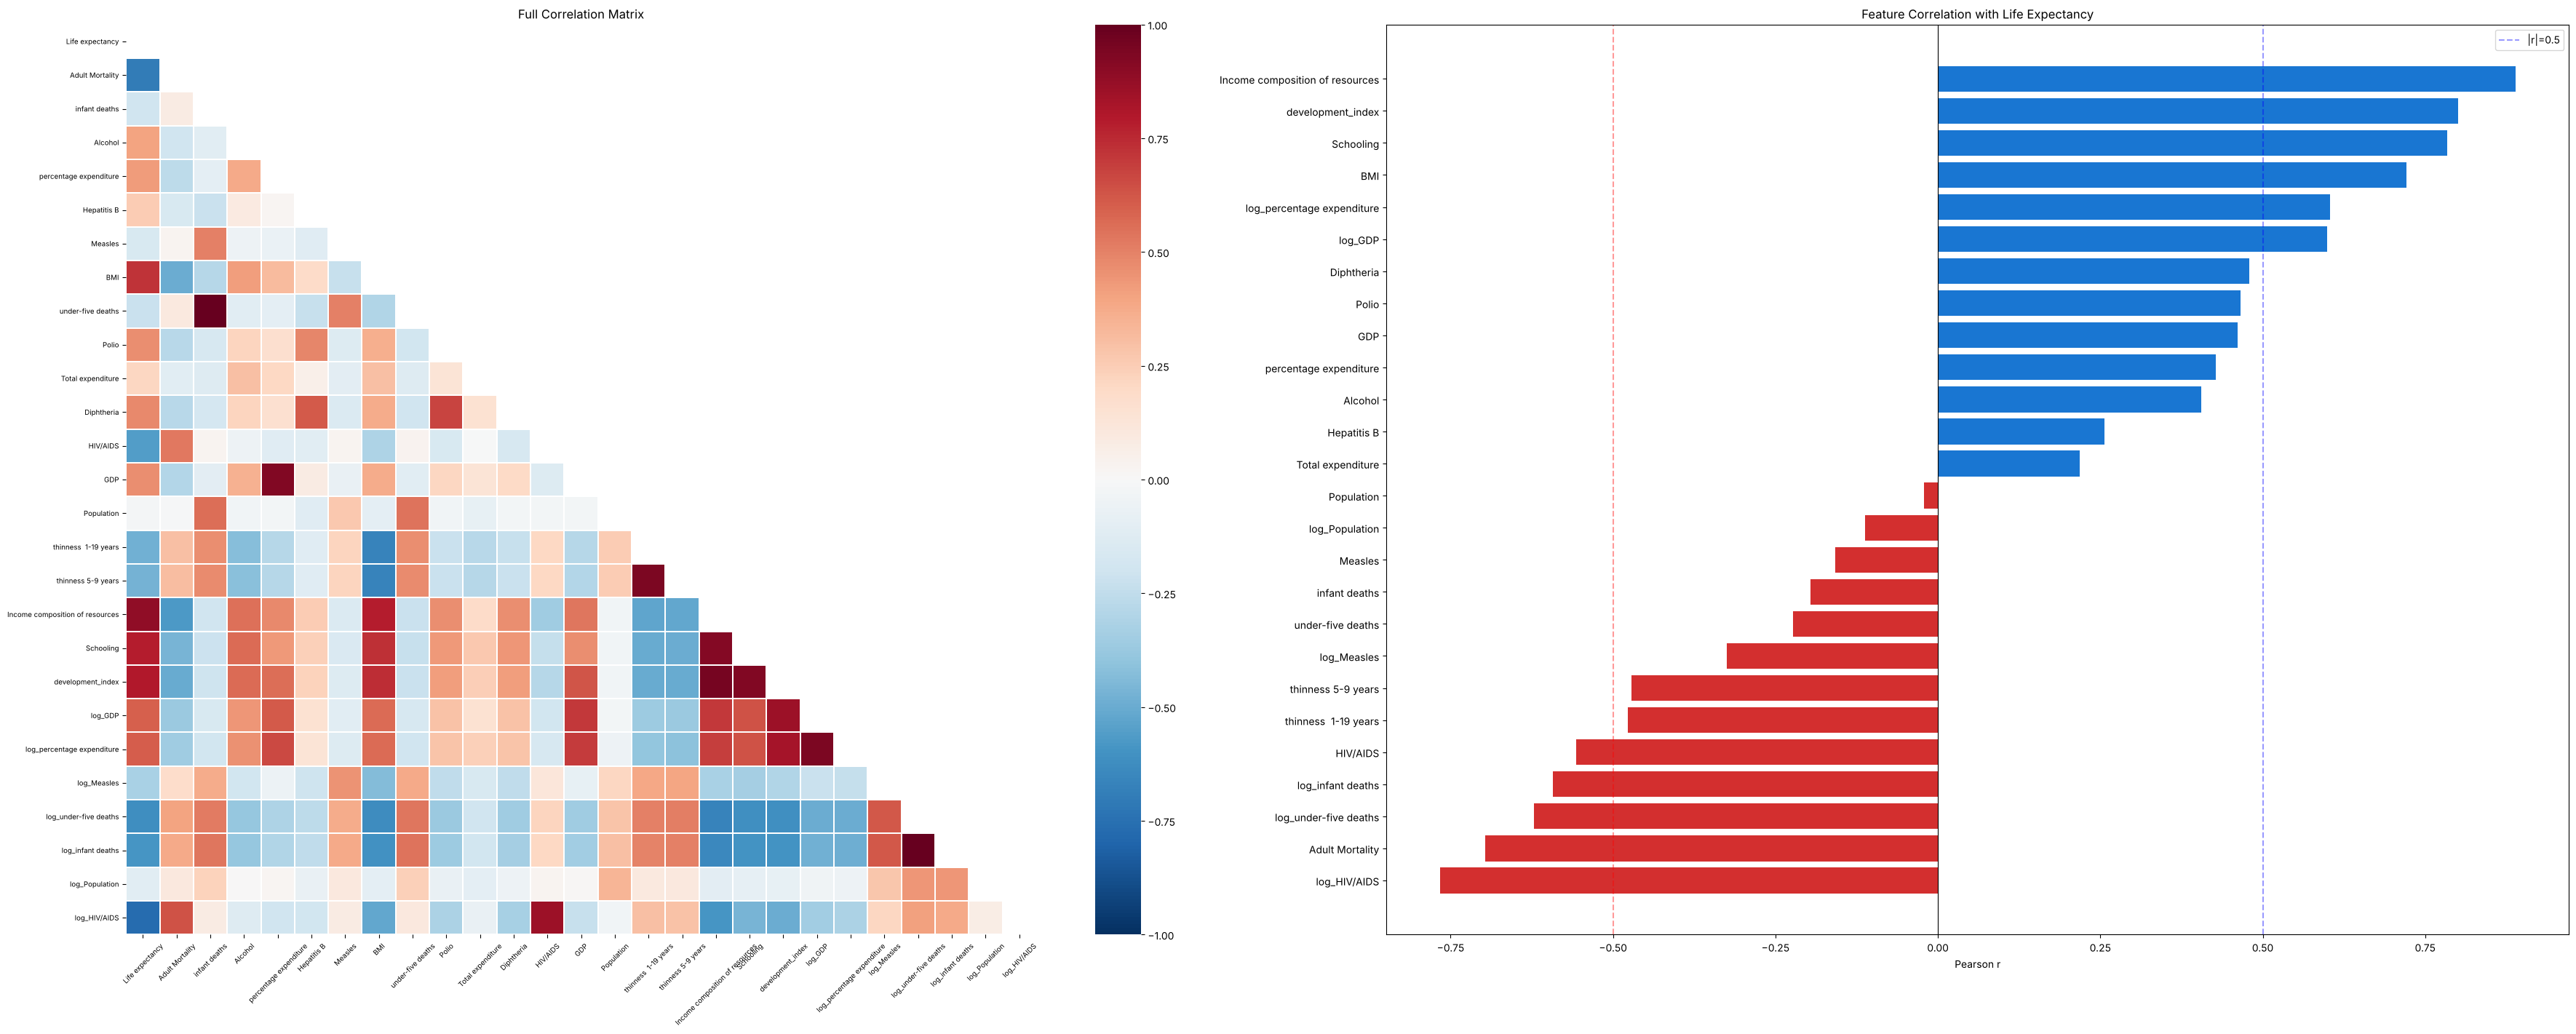

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(36, 14))

# Plot 1: Full correlation heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    ax=axes[0],
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    annot=False,         
    linewidths=0.3,
    square=True
)
axes[0].set_title('Full Correlation Matrix', fontsize=12)
axes[0].tick_params(axis='x', rotation=45, labelsize=7)
axes[0].tick_params(axis='y', labelsize=7)

# Plot 2: Korelasi fitur vs Life Expectancy saja
colors = ['#d32f2f' if v < 0 else '#1976d2' for v in target_corr]
axes[1].barh(target_corr.index, target_corr.values, color=colors)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].axvline(0.5, color='blue', linestyle='--', alpha=0.4, label='|r|=0.5')
axes[1].axvline(-0.5, color='red', linestyle='--', alpha=0.4)
axes[1].set_title('Feature Correlation with Life Expectancy', fontsize=12)
axes[1].set_xlabel('Pearson r')
axes[1].legend()

plt.tight_layout()
plt.show()

#### Temuan:
1. Fitur yang sudah ditransformasi log punya korelasi (nilai absolut) yang lebih tinggi dengan life expectancy dibandingkan fitur mentahnya. Ke depannya, versi log yang dipakai untuk analisis.
2. `Population` maupun `log_Population` punya korelasi yang sangat lemah dengan life expectancy. Fitur ini juga terbukti inkonsisten dan banyak error, sehingga keduanya di-drop.

### Identifikasi Pasangan Multikolinear

In [35]:
threshold = 0.85 # rule of thumb untuk multicollinearity
high_corr_pairs = []

cols = [
    'Life expectancy', 'Adult Mortality', 'Alcohol', 'Hepatitis B', 'BMI', 'Polio', 'Total expenditure', 'Diphtheria', 'thinness  1-19 years',
    'thinness 5-9 years', 'Income composition of resources',
    'Schooling', 'development_index', 'log_GDP', 'log_percentage expenditure', 'log_Measles',
    'log_under-five deaths', 'log_infant deaths', 'log_Population',
    'log_HIV/AIDS'
]
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_matrix.loc[cols[i], cols[j]]
        if abs(r) > threshold and cols[i] != 'Life expectancy' and cols[j] != 'Life expectancy':
            high_corr_pairs.append({
                'Feature A': cols[i],
                'Feature B': cols[j],
                'r': round(r, 4)
            })

pairs_df = pd.DataFrame(high_corr_pairs).sort_values('r', key=abs, ascending=False)
print(f"=== Highly Collinear Pairs (|r| > {threshold}) ===")
print(pairs_df.to_string(index=False))

=== Highly Collinear Pairs (|r| > 0.85) ===
                      Feature A                  Feature B    r
          log_under-five deaths          log_infant deaths 1.00
Income composition of resources          development_index 0.96
                        log_GDP log_percentage expenditure 0.94
           thinness  1-19 years         thinness 5-9 years 0.94
                      Schooling          development_index 0.93
Income composition of resources                  Schooling 0.92
              development_index                    log_GDP 0.86


#### Temuan:
1. `log_under-five deaths` dan `log_infant deaths` berkorelasi hampir sempurna (r ≈ 1,00). Secara statistik, keduanya membawa informasi yang hampir identik. Penjelasan yang paling mungkin: keduanya tampaknya absolute count (lihat Phase 1), sehingga sama-sama ikut besar atau kecil mengikuti jumlah penduduk negara. Selain itu, sebagian besar kematian balita memang terjadi pada tahun pertama kehidupan. Karena informasinya sama, salah satunya di-drop.
2. `thinness 1-19 years` dengan `thinness 5-9 years`, serta `log_GDP` dengan `log_percentage expenditure`, juga berkorelasi sangat tinggi. Salah satu dari tiap pasangan bisa di-drop.
3. `development_index`, `Income composition of resources`, `Schooling`, dan `log_GDP` saling berkorelasi kuat. Ini wajar karena `development_index` dibentuk dari tiga fitur lainnya. Jadi `development_index` sudah mewakili ketiga fitur tersebut, dan ketiganya bisa di-drop.

### Spearman vs Pearson: Deteksi Non-linearity

In [36]:
# Ide: kalau Spearman jauh lebih tinggi dari Pearson untuk suatu fitur,
# berarti hubungannya monotonic tapi non-linear.
# Delta besar = kandidat untuk transformasi (log, sqrt, dll.)

numeric_features = [c for c in analysis_cols if c != 'Life expectancy']

pearson_corr = df[analysis_cols].corr(method='pearson')['Life expectancy'].drop('Life expectancy')
spearman_corr = df[analysis_cols].corr(method='spearman')['Life expectancy'].drop('Life expectancy')

linearity_df = pd.DataFrame({
    'Pearson': pearson_corr,
    'Spearman': spearman_corr,
    'Delta (Spearman - Pearson)': spearman_corr - pearson_corr
}).sort_values('Delta (Spearman - Pearson)', key=abs, ascending=False)

print("=== Pearson vs Spearman Correlation with Life Expectancy ===")
print("(Large |Delta| = non-linear relationship)")
print(linearity_df.round(4).to_string())

=== Pearson vs Spearman Correlation with Life Expectancy ===
(Large |Delta| = non-linear relationship)
                                 Pearson  Spearman  Delta (Spearman - Pearson)
infant deaths                      -0.20     -0.60                       -0.40
under-five deaths                  -0.22     -0.62                       -0.40
percentage expenditure              0.43      0.65                        0.22
HIV/AIDS                           -0.56     -0.75                       -0.20
GDP                                 0.46      0.64                        0.18
thinness 5-9 years                 -0.47     -0.62                       -0.15
thinness  1-19 years               -0.48     -0.61                       -0.13
Measles                            -0.16     -0.28                       -0.12
Hepatitis B                         0.26      0.35                        0.09
Total expenditure                   0.22      0.29                        0.08
Polio                       

#### Temuan:
1. Fitur mentah seperti `infant deaths`, `under-five deaths`, `percentage expenditure`, `HIV/AIDS`, dan `GDP` punya |Delta| Spearman−Pearson yang jauh lebih besar dibandingkan versi log-nya. Artinya hubungannya monotonic tetapi non-linear, dan log transform membuat hubungannya lebih linear. Karena itu versi log yang dipakai, dan fitur mentahnya di-drop.
2. Untuk pasangan multikolinear yang tersisa:
   - **thinness:** `thinness 5-9 years` di-drop, dan `thinness 1-19 years` dipertahankan. Alasannya, `thinness 1-19 years` punya korelasi sedikit lebih tinggi dengan target (−0,48 vs −0,47) dan hubungannya sedikit lebih linear (|Delta| 0,13 vs 0,15). Perbedaannya kecil, jadi memilih yang mana pun tidak banyak mengubah hasil.
   - **GDP dan percentage expenditure:** `log_percentage expenditure` di-drop karena berkorelasi 0,94 dengan `log_GDP`. `log_GDP` sendiri juga di-drop karena sudah menjadi komponen `development_index`.

### Temuan Phase 3 — Ringkasan

**Fitur paling prediktif (di feature set final):** `development_index` (r = +0,80), `log_HIV/AIDS` (r = −0,77), `Adult Mortality` (r = −0,70). Sebagai catatan, `Income composition of resources` sebenarnya punya korelasi tertinggi (r = +0,89), tetapi di-drop karena sudah terwakili oleh `development_index`.

**Non-linearity terdeteksi lewat delta Pearson−Spearman:**
`infant deaths` dan `under-five deaths` (Δ = −0,40), `percentage expenditure` (Δ = +0,22), `HIV/AIDS` (Δ = −0,20). Masalah ini diatasi dengan log transform. Contohnya, korelasi `under-five deaths` naik dari −0,22 (mentah) menjadi −0,62 (`log_under-five deaths`).

**Keputusan feature drop:**

| Fitur di-drop | Kriteria | Alasan |
|---|---|---|
| `log_infant deaths` | Collinearity | r ≈ 1,00 dengan `log_under-five deaths` |
| `Income composition of resources` | Collinearity | r = 0,96 dengan `development_index`, sudah terwakili |
| `log_percentage expenditure` | Collinearity | r = 0,94 dengan `log_GDP` |
| `thinness 5-9 years` | Collinearity | r = 0,94 dengan `thinness 1-19 years` |
| `Schooling` | Collinearity | r = 0,93 dengan `development_index`, sudah terwakili |
| `log_GDP` | Collinearity | r = 0,86 dengan `development_index`; sudah menjadi komponen index |
| `infant deaths`, `under-five deaths`, `HIV/AIDS`, `GDP`, `Measles`, `percentage expenditure` | Versi log lebih baik | Log transform menaikkan korelasi Pearson secara signifikan |
| `Population`, `log_Population` | Data tidak reliable | Nilai tidak konsisten (Maldives 2003 = 34; India 2000 ≈ 1,5 juta vs 2001 ≈ 171 juta) |
| `Status`, `Status_encoded` | Digantikan | `development_index` berkorelasi jauh lebih tinggi (r = 0,48 → 0,80) |

**Hasil:** 12 prediktor final. |r| tertinggi antar prediktor final adalah 0,74 (`BMI` vs `development_index`), masih di bawah threshold 0,85 (dicek di cell berikut).

In [37]:
cols_to_drop = [
    # Redundant — collinear dengan versi log
    'infant deaths', 'under-five deaths', 'HIV/AIDS',
    'GDP', 'Measles', 'percentage expenditure',
    # Redundant — log version collinear dengan yang lebih baik
    'log_infant deaths', 'log_percentage expenditure', 'log_GDP',
    # Redundant — terabsorb dalam development_index
    'Income composition of resources', 'Schooling',
    # Redundant — collinear dengan thinness 1-19
    'thinness 5-9 years',
    # Unit tidak reliable
    'Population', 'log_Population',
    # Digantikan oleh development_index
    'Status', 'Status_encoded'
]

# Apply ke dataframe baru
df_model = df.drop(columns=[c for c in cols_to_drop if c in df.columns]).copy()

print(f"\nFitur tersisa: {df_model.shape[1]} kolom")
print(df_model.columns.tolist())

predictors = [c for c in df_model.select_dtypes(include=np.number).columns
              if c not in ['Year', 'Life expectancy']]

print()
print(f"=== FINAL {len(predictors)} PREDICTORS ===\n")
final_corr = df_model[predictors].corrwith(df_model['Life expectancy']).sort_values()
for col, r in final_corr.items():
    bar = '█' * int(abs(r) * 20)
    direction = '[-]' if r < 0 else '[+]'
    print(f"  {direction} {col:30s} r={r:+.4f}  {bar}")

print(f"\nTotal: {len(predictors)} prediktor")

# Cek multicollinearity yang tersisa di antara prediktor final
pred_corr = df_model[predictors].corr().abs()
upper = pred_corr.where(np.triu(np.ones(pred_corr.shape, dtype=bool), k=1))
max_pair = upper.stack().idxmax()
print(f"\n|r| tertinggi antar prediktor final: {upper.stack().max():.4f} {max_pair}")


Fitur tersisa: 15 kolom
['Country', 'Year', 'Life expectancy', 'Adult Mortality', 'Alcohol', 'Hepatitis B', 'BMI', 'Polio', 'Total expenditure', 'Diphtheria', 'thinness  1-19 years', 'log_Measles', 'log_under-five deaths', 'log_HIV/AIDS', 'development_index']

=== FINAL 12 PREDICTORS ===

  [-] log_HIV/AIDS                   r=-0.7663  ███████████████
  [-] Adult Mortality                r=-0.6964  █████████████
  [-] log_under-five deaths          r=-0.6214  ████████████
  [-] thinness  1-19 years           r=-0.4772  █████████
  [-] log_Measles                    r=-0.3249  ██████
  [+] Total expenditure              r=+0.2181  ████
  [+] Hepatitis B                    r=+0.2568  █████
  [+] Alcohol                        r=+0.4049  ████████
  [+] Polio                          r=+0.4656  █████████
  [+] Diphtheria                     r=+0.4795  █████████
  [+] BMI                            r=+0.7213  ██████████████
  [+] development_index              r=+0.8002  ████████████████



## Phase 4: Thematic Deep-Dive Insights

1. **Imunisasi: Threshold Effect** — 
   di mana marginal benefit terbesar terjadi?
2. **Alkohol: Weird Correlation** — 
   mengapa Alkohol memiliki korelasi yang positif terhadap life expectancy?

### Imunisasi: Threshold Effect

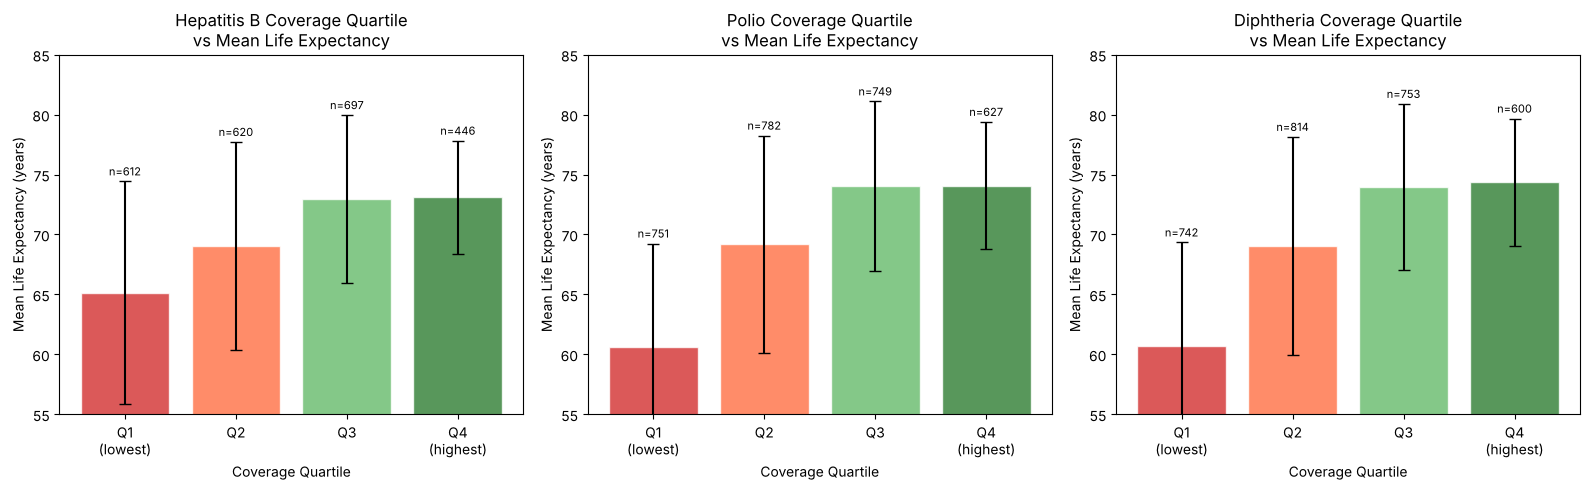

=== LE Jump antar Quartile per Vaksin ===

Hepatitis B:
vax_bin
Q2   3.89
Q3   3.91
Q4   0.13
  → Jump terbesar: Q3 (3.91 tahun)


  Batas kuartil coverage (%): [1.0, 77.0, 92.0, 97.0, 99.0]

Polio:
vax_bin
Q2   8.55
Q3   4.86
Q4   0.03
  → Jump terbesar: Q2 (8.55 tahun)
  Batas kuartil coverage (%): [3.0, 78.0, 93.0, 97.0, 99.0]

Diphtheria:
vax_bin
Q2   8.31
Q3   4.95
Q4   0.39
  → Jump terbesar: Q2 (8.31 tahun)
  Batas kuartil coverage (%): [2.0, 78.0, 93.0, 97.0, 99.0]


In [38]:
# Hipotesis: imunisasi punya efek threshold — di bawah coverage tertentu,
# penyakit mewabah dan efeknya non-linear terhadap LE.

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
vaccine_cols = ['Hepatitis B', 'Polio', 'Diphtheria']

for i, col in enumerate(vaccine_cols):
    # Bin coverage ke dalam 4 quartile
    df_model['vax_bin'] = pd.qcut(df_model[col].dropna(), q=4, 
                                   labels=['Q1\n(lowest)', 'Q2', 'Q3', 'Q4\n(highest)'])
    
    vax_grouped = df_model.groupby('vax_bin', observed=True)['Life expectancy'].agg(
        ['mean', 'std', 'count']
    ).reset_index()
    
    axes[i].bar(vax_grouped['vax_bin'], vax_grouped['mean'],
                yerr=vax_grouped['std'], capsize=4,
                color=['#d32f2f', '#ff7043', '#66bb6a', '#2e7d32'],
                alpha=0.8, edgecolor='white')
    axes[i].set_title(f'{col} Coverage Quartile\nvs Mean Life Expectancy')
    axes[i].set_xlabel('Coverage Quartile')
    axes[i].set_ylabel('Mean Life Expectancy (years)')
    axes[i].set_ylim(55, 85)
    
    # Annotate jumlah data per bin
    for _, row in vax_grouped.iterrows():
        axes[i].text(row['vax_bin'], row['mean'] + row['std'] + 0.5,
                    f"n={int(row['count'])}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()

# Hitung jump terbesar: antara quartile mana?
print("=== LE Jump antar Quartile per Vaksin ===")
for col in vaccine_cols:
    df_model['vax_bin'] = pd.qcut(df_model[col].dropna(), q=4,
                                   labels=['Q1', 'Q2', 'Q3', 'Q4'])
    means = df_model.groupby('vax_bin', observed=True)['Life expectancy'].mean()
    jumps = means.diff().dropna()
    print(f"\n{col}:")
    print(jumps.round(2).to_string())
    print(f"  → Jump terbesar: {jumps.abs().idxmax()} ({jumps.abs().max():.2f} tahun)")
    # Batas coverage (%) tiap kuartil, supaya "threshold" punya angka konkret
    _, edges = pd.qcut(df_model[col].dropna(), q=4, retbins=True)
    print(f"  Batas kuartil coverage (%): {np.round(edges, 1).tolist()}")

df_model = df_model.drop(columns='vax_bin')  # kolom bantu, tidak dipakai lagi

#### Temuan:
- **Polio dan Diphtheria:** kenaikan life expectancy terbesar terjadi dari kuartil 1 ke kuartil 2 (sekitar +8,3 sampai +8,6 tahun), lalu mengecil di Q2→Q3, dan hampir nol di Q3→Q4. Dalam angka coverage, lompatan terbesar terjadi antara negara dengan coverage di bawah ~78% dan negara dengan coverage ~78–93%; di atas ~97% hampir tidak ada perbedaan.
- **Hepatitis B:** kenaikannya lebih merata di Q1→Q2 dan Q2→Q3 (masing-masing sekitar +3,9 tahun), lalu hampir nol di Q3→Q4.

Ketiganya menunjukkan pola *diminishing returns*: setelah coverage cukup tinggi, tambahan coverage hampir tidak berkaitan dengan kenaikan life expectancy. Catatan: ini hubungan korelasional. Negara dengan coverage rendah umumnya juga lebih miskin, sehingga sebagian perbedaan ini kemungkinan ikut dipengaruhi tingkat pembangunan (seperti kasus Alcohol di bawah).

### Alkohol: Weird Correlation

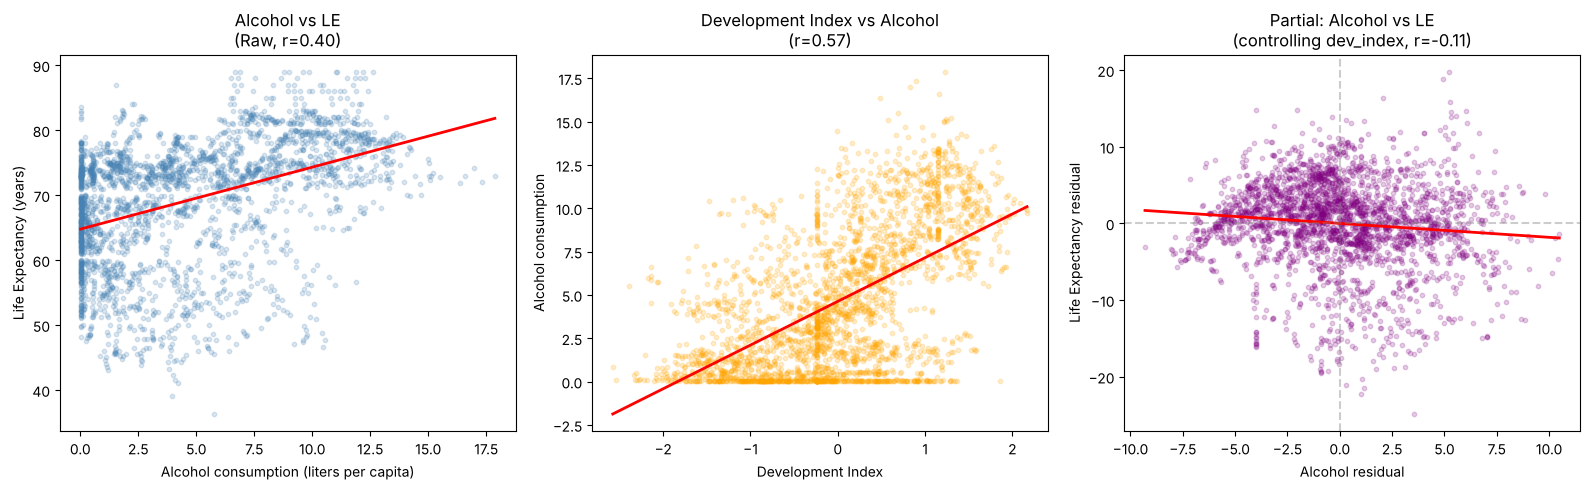

Korelasi Alcohol vs LE (raw)                    : 0.4049
Korelasi Alcohol vs development_index           : 0.5692
Korelasi Alcohol vs LE (partial, control=dev)   : -0.1059



Kesimpulan: korelasi berubah dari 0.40 → -0.11 setelah control


In [39]:
# Alcohol punya korelasi POSITIF +0.40 dengan LE (counterintuitive).
# Alkohol seharusnya merusak kesehatan. Kenapa korelasinya positif?
# Hipotesis: alcohol adalah indikator kemakmuran. Negara kaya minum lebih banyak, 
# dan negara kaya juga punya LE lebih tinggi.

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Raw scatter — Alcohol vs LE (tampak positif)
axes[0].scatter(df_model['Alcohol'], df_model['Life expectancy'],
               alpha=0.2, s=10, color='steelblue')
# Fit line
clean = df_model[['Alcohol', 'Life expectancy']].dropna()
z = np.polyfit(clean['Alcohol'], clean['Life expectancy'], 1)
x_range = np.linspace(clean['Alcohol'].min(), clean['Alcohol'].max(), 100)
axes[0].plot(x_range, np.poly1d(z)(x_range), color='red', linewidth=2)
axes[0].set_title(f'Alcohol vs LE\n(Raw, r={clean.corr().iloc[0,1]:.2f})')
axes[0].set_xlabel('Alcohol consumption (liters per capita)')
axes[0].set_ylabel('Life Expectancy (years)')

# Plot 2: Alcohol vs development_index. Apakah negara kaya memang minum lebih banyak?
clean2 = df_model[['Alcohol', 'development_index']].dropna()
axes[1].scatter(df_model['development_index'], df_model['Alcohol'],
               alpha=0.2, s=10, color='orange')
z2 = np.polyfit(clean2['development_index'], clean2['Alcohol'], 1)
x2 = np.linspace(clean2['development_index'].min(), clean2['development_index'].max(), 100)
axes[1].plot(x2, np.poly1d(z2)(x2), color='red', linewidth=2)
r_alc_dev = clean2.corr().iloc[0,1]
axes[1].set_title(f'Development Index vs Alcohol\n(r={r_alc_dev:.2f})')
axes[1].set_xlabel('Development Index')
axes[1].set_ylabel('Alcohol consumption')

# Plot 3: Partial residual — Alcohol vs LE setelah control development_index
from scipy.stats import linregress

def partial_residual(df, target, predictor, control):
    """Return residuals dari target dan predictor setelah keduanya di-regress on control."""
    clean = df[[target, predictor, control]].dropna()
    fit_t = linregress(clean[control], clean[target])     # regresi target ~ control
    fit_p = linregress(clean[control], clean[predictor])  # regresi predictor ~ control
    res_target = clean[target] - (fit_t.slope * clean[control] + fit_t.intercept)
    res_pred = clean[predictor] - (fit_p.slope * clean[control] + fit_p.intercept)
    return res_pred, res_target

res_alc, res_le = partial_residual(df_model, 'Life expectancy', 'Alcohol', 'development_index')
axes[2].scatter(res_alc, res_le, alpha=0.2, s=10, color='purple')
z3 = np.polyfit(res_alc, res_le, 1)
x3 = np.linspace(res_alc.min(), res_alc.max(), 100)
axes[2].plot(x3, np.poly1d(z3)(x3), color='red', linewidth=2)
partial_r = np.corrcoef(res_alc, res_le)[0, 1]
axes[2].set_title(f'Partial: Alcohol vs LE\n(controlling dev_index, r={partial_r:.2f})')
axes[2].set_xlabel('Alcohol residual')
axes[2].set_ylabel('Life Expectancy residual')
axes[2].axhline(0, color='gray', linestyle='--', alpha=0.4)
axes[2].axvline(0, color='gray', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Korelasi Alcohol vs LE (raw)                    : {df_model[['Alcohol','Life expectancy']].corr().iloc[0,1]:.4f}")
print(f"Korelasi Alcohol vs development_index           : {r_alc_dev:.4f}")
print(f"Korelasi Alcohol vs LE (partial, control=dev)   : {partial_r:.4f}")
print(f"\nKesimpulan: korelasi berubah dari {df_model[['Alcohol','Life expectancy']].corr().iloc[0,1]:.2f} → {partial_r:.2f} setelah control")

#### Temuan:
Korelasi Alcohol dengan LE berubah dari +0,40 menjadi −0,11 setelah efek `development_index` dikontrol (*partial correlation*). Alcohol juga berkorelasi +0,57 dengan `development_index`. Artinya negara yang lebih maju cenderung mengonsumsi lebih banyak alkohol sekaligus punya LE lebih tinggi. Korelasi positif awal kemungkinan besar muncul karena keduanya sama-sama terkait tingkat pembangunan (*confounding*), bukan karena alkohol menaikkan LE. Setelah dikontrol, hubungannya lemah dan sedikit negatif.

Catatan: partial correlation tetap analisis korelasional, jadi tidak membuktikan hubungan sebab-akibat ke arah mana pun.

---
## Phase 5 — Synthesis: Implikasi untuk Prediksi Life Expectancy

### Hierarki Prediktor

Berdasarkan seluruh analisis, prediktor diranking berdasarkan
*genuine predictive power* pada feature set final (12 prediktor):

| Tier | Prediktor | r vs LE | Catatan |
|---|---|---|---|
| **Tier 1** | `development_index` | +0.80 | Strongest overall; menggantikan Status + Schooling + ICR |
| **Tier 1** | `log_HIV/AIDS` | −0.77 | Log transform kritis — raw hanya −0.56 |
| **Tier 1** | `BMI` | +0.72 | Korelasinya kuat, tapi nilai kolom ini sebagian besar tidak masuk akal (lihat Phase 1). Perlakukan dengan hati-hati |
| **Tier 1** | `Adult Mortality` | −0.70 | Strongest direct mortality predictor |
| **Tier 2** | `log_under-five deaths` | −0.62 | Log transform kritis — raw hanya −0.22 |
| **Tier 2** | `Diphtheria`, `Polio` | +0.47–0.48 | Diminishing returns: kenaikan LE terbesar di coverage rendah→menengah |
| **Tier 3** | `thinness 1-19 years` | −0.48 | Reliable, unit valid |
| **Tier 3** | `Hepatitis B` | +0.26 | Missing tinggi (18,8%) dan pola missing berbeda antar `Status` |
| **Tier 3** | `log_Measles` | −0.32 | Absolute count — proxy beban penyakit, bukan rate |
| **Tier 4** | `Total expenditure` | +0.22 | Signal lemah; gunakan sebagai kontrol saja |
| **Tier 4** | `Alcohol` | +0.40 | r = −0,11 setelah dikontrol `development_index` (confounding) |

---

### Rekomendasi untuk Modeling

1. **Jangan gunakan `Status` biner** — `development_index` berkorelasi
   jauh lebih tinggi dengan target (r = 0,48 → 0,80) dan tidak terpengaruh label yang salah.

2. **Log transform wajib** untuk `HIV/AIDS`, `under-five deaths`,
   dan `Measles` — ketiganya adalah count/skewed data di mana
   Pearson raw severely underestimate kekuatan hubungan sebenarnya

3. **Hati-hati dengan `Alcohol`** — korelasi raw +0,40 menjadi −0,11 setelah dikontrol `development_index`.

4. **Imputasi per grup** — karena pola missing bergantung pada `Status`, imputasi sebaiknya dilakukan per grup (atau berdasarkan `development_index`), bukan satu nilai global.

5. **Pertimbangkan ulang `BMI`** — korelasinya tinggi, tetapi nilai kolomnya sebagian besar tidak masuk akal sebagai rata-rata BMI nasional.

---

### Keterbatasan Dataset

| Keterbatasan | Detail | Implikasi |
|---|---|---|
| **Misklasifikasi `Status`** | France, Canada, Finland, Israel, Greece terklasifikasi Developing | Jangan gunakan `Status` sebagai ground truth |
| **Missing bergantung pada `Status`** | Pola berbeda per fitur dan per grup; konsisten dengan MAR terhadap `Status`. MNAR tidak bisa dipastikan dari data teramati | Imputasi global bisa menimbulkan bias; gunakan imputasi per grup |
| **Unit inconsistency** | `Population` terbukti tidak konsisten (Maldives 2003 = 34; India 2000 ≈ 1,5 juta vs 2001 ≈ 171 juta); `Measles`, `infant deaths`, `under-five deaths` kemungkinan adalah absolute count bukan rate; `percentage expenditure` kemungkinan bukan persentase | Fitur-fitur ini tidak comparable antar negara tanpa normalisasi yang valid |
| **Data entry error / unit BMI** | `BMI` < 10 pada 283 baris (Vietnam, Bangladesh, dll.) dan lebih dari separuh baris > 40 — keduanya tidak masuk akal untuk rata-rata populasi | BMI < 10 sudah → NaN; seluruh kolom tetap tidak reliable dan sumber error tidak diketahui |